# CHQ vs Cahn–Hilliard: elastic coupling suppresses phase separation

This notebook runs the SAV-BDF2 solver (`chq_sav.py`) on the coupled-vs-uncoupled comparison from the paper (“Coupled-vs-uncoupled demonstration”): the full CHQ model (viscoelastic phase separation, elastic field $q$ coupled through $A(\phi)$) against its $A\equiv0$ control, which reduces \eqref{eq:chq-phi} to plain Cahn–Hilliard with the same mobility $b(\phi)$.

Two parts:
1. A short (under a minute) **live** run of both models at the paper's resolution ($N=128$), to show the solver actually executing end to end.
2. The **full comparison from the paper** ($N=128$, $\Delta t=10^{-3}$, $T=10$, i.e. 10,000 BDF2 steps): the $\phi$-morphology snapshots at $t=0,1,2,3,4$ and the energy-vs-time curve. Running this live is not practical here — the original runs took **11.7 h** (coupled model, median 333 GMRES iterations/step) and **19 min** ($A\equiv0$ control, median 16 iterations/step), measured wall-clock times recorded when the paper's figures were generated. So this part loads the saved results in `../data/` (extracted from those runs, kept small — a few MB rather than the 72 MB of raw snapshots).

In [8]:
%matplotlib inline
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join("..", "chq_sav")))

import numpy as np
import matplotlib.pyplot as plt
import scienceplots 
plt.style.use(['science'])
import chq_sav as sav
from chqpy_coef import chqpy_coefficients, make_ic
from dealias import dealias_filter

plt.rcParams.update({
    "text.usetex": True,
    "text.latex.preamble": r"""
        \usepackage{amsmath}
        \usepackage{amssymb}
        \usepackage{type1cm}
    """,
    "font.size": 18,
    "axes.titlesize": 16,
    "axes.labelsize": 16,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 14,
})

## Part 1 — short live run (both models, $N=128$, 60 steps, $T=0.06$)

In [2]:
N = 128
dt = 1e-3
n_demo_steps = 60
snap_every = 15  # -> 5 snapshots including t=0

g = sav.SpectralGrid2D(N, N, 1.0, 1.0)
C0 = sav.C0_DEFAULT


def run_demo(case):
    coef = chqpy_coefficients(gamma=1e-3, W=3.0)
    if case == "noA":
        coef = sav.without_coupling(coef)
    phi0, q0 = make_ic(N, seed=12345)
    r0 = float(np.sqrt(g.integ(coef.f(phi0)) + C0))
    s0 = (phi0.copy(), q0.copy(), r0)

    snaps_t, snaps_phi, iters_log = [0.0], [phi0.copy()], []

    s1 = sav.startup(g, coef, s0, dt, C0, backend="gmres", method="be", gmres_tol=1e-10)
    s1 = (dealias_filter(g, s1[0]), dealias_filter(g, s1[1]), s1[2])
    s_prev, s_cur = s0, s1
    t = dt
    for n in range(1, n_demo_steps):
        s_next, mu_next, fz, info = sav.bdf2_step(g, coef, s_prev, s_cur, dt, C0,
                                                    backend="gmres", gmres_tol=1e-10)
        s_next = (dealias_filter(g, s_next[0]), dealias_filter(g, s_next[1]), s_next[2])
        iters_log.append(info.iters)
        t += dt
        if (n + 1) % snap_every == 0:
            snaps_t.append(t)
            snaps_phi.append(s_next[0].copy())
        s_prev, s_cur = s_cur, s_next
    return np.array(snaps_t), snaps_phi, iters_log


demo = {}
for case in ("full", "noA"):
    demo[case] = run_demo(case)
    its = demo[case][2]
    print(f"{case}: GMRES iters over the run -> min {min(its)}, max {max(its)}")

full: GMRES iters over the run -> min 9, max 282
noA: GMRES iters over the run -> min 4, max 17


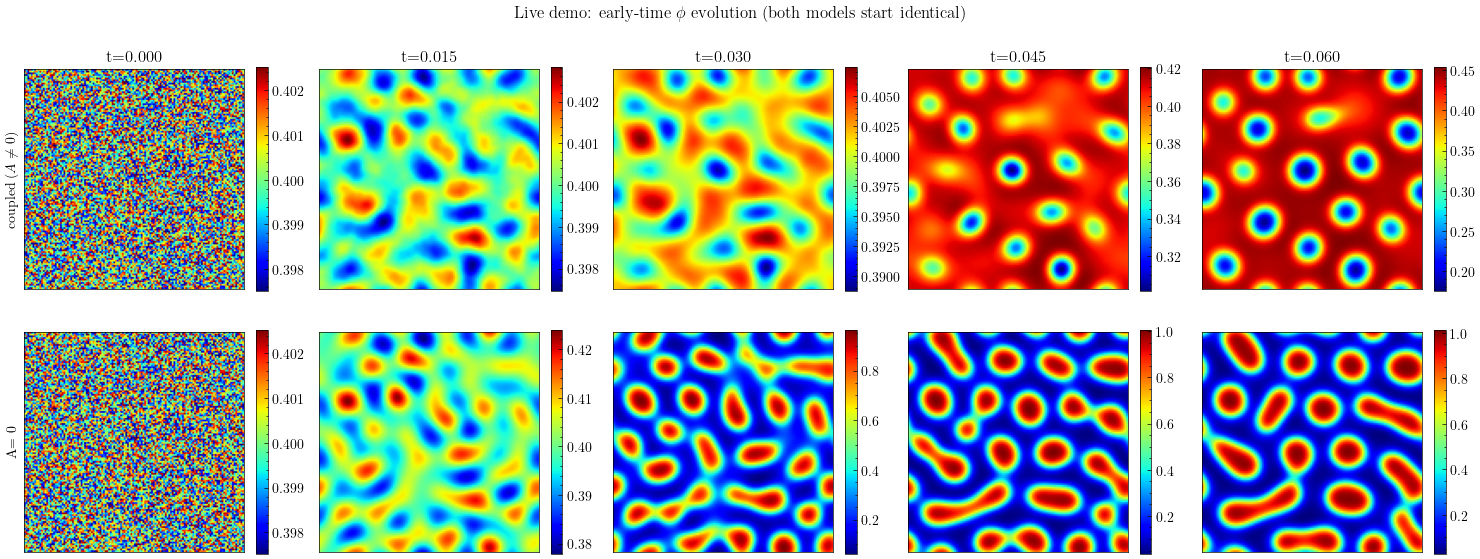

In [5]:
labels = {"full": "coupled ($A \\neq 0$)", "noA": "A= 0"}
ncols = len(demo["full"][0])
fig, axes = plt.subplots(2, ncols, figsize=(3 * ncols, 6))
for i, case in enumerate(("full", "noA")):
    ts, phis, _ = demo[case]
    for j, (t, phi) in enumerate(zip(ts, phis)):
        ax = axes[i, j]
        im = ax.imshow(phi.T, origin="lower", cmap="jet", extent=[0, 1, 0, 1])
        if i == 0:
            ax.set_title(f"t={t:.3f}")
        ax.set_xticks([])
        ax.set_yticks([])
        plt.colorbar(im, ax=ax, fraction=0.046)
    axes[i, 0].set_ylabel(labels[case])
fig.suptitle("Live demo: early-time $\\phi$ evolution (both models start identical)")
plt.tight_layout()
plt.show()

## Part 2 — full comparison from the paper ($T=10$), loaded from saved data

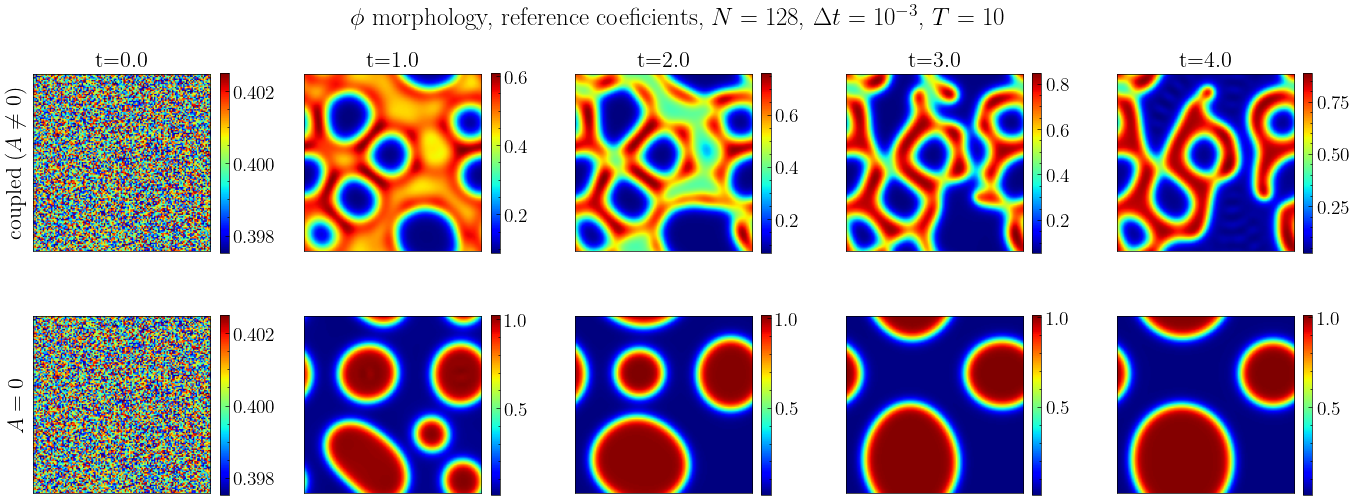

In [31]:
data_dir = os.path.join("..", "data")
snap_coupled = np.load(os.path.join(data_dir, "snapshots_coupled.npz"))
snap_noA = np.load(os.path.join(data_dir, "snapshots_noA.npz"))

rows = [("coupled ($A\\neq$ 0)", snap_coupled), ("$A=0$", snap_noA)]
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for i, (label, d) in enumerate(rows):
    for j in range(5):
        phi = d["phi"][j]
        ax = axes[i, j]
        im = ax.imshow(phi.T, origin="lower", cmap="jet",
                        vmin=phi.min(), vmax=phi.max(), extent=[0, 1, 0, 1])
        if i == 0:
            ax.set_title(f"t={d['t'][j]:.1f}")
        ax.set_xticks([])
        ax.set_yticks([])
        plt.colorbar(im, ax=ax, fraction=0.046)
    axes[i, 0].set_ylabel(label)
fig.suptitle("$\\phi$ morphology, reference coeficients, $N=128$, $\\Delta t=10^{-3}$, $T=10$",fontsize=18,y=0.92)
plt.tight_layout()
plt.savefig("Figs/fig_chqpy_W3_morph.pdf")
plt.show()

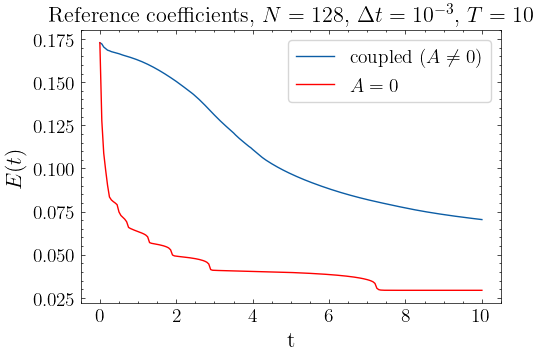

In [32]:
e_coupled = np.load(os.path.join(data_dir, "energy_coupled.npz"))
e_noA = np.load(os.path.join(data_dir, "energy_noA.npz"))

plt.figure(figsize=(5.5, 4))
plt.plot(e_coupled["t"], e_coupled["E"], label="coupled ($A \\neq 0$)")
plt.plot(e_noA["t"], e_noA["E"], label="$A=0$",color="red")
plt.xlabel("t")
plt.ylabel("$E(t)$")
plt.title("Reference coefficients, $N=128$, $\\Delta t=10^{-3}$, $T=10$")
plt.legend(frameon=True)
plt.tight_layout()
plt.savefig("Figs/fig_chqpy_W3_energy.pdf")
plt.show()